# Linkage Disequilibrium

Measure association between alleles at two loci from known phased chromosome copies.

D is the joint frequency of both alternate alleles minus the product of their marginal frequencies. Squaring and scaling it by the two Bernoulli variances gives r². A monomorphic locus has zero variance and yields undefined r².

In [1]:
from pathlib import Path
import sys

here = Path.cwd()
sys.path.insert(0, str(here.parent))
import numpy as np
import matplotlib.pyplot as plt

from itertools import product

## Worked example

Run the example from top to bottom. The printed check and figure use the same observations.

Phased copies 100 | D 0.120 | r² 0.234


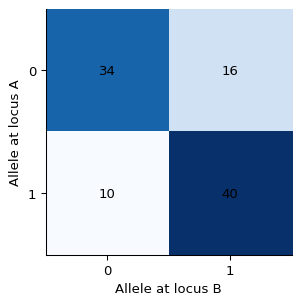

In [2]:
table = np.array([[34, 16], [10, 40]])
p = table / table.sum()
px = p[1].sum()
py = p[:, 1].sum()
D = p[1, 1] - px * py
r2 = D**2 / (px * (1 - px) * py * (1 - py))
pairs = np.repeat(np.array(list(product([0, 1], repeat=2))), table.ravel(), axis=0)
assert np.isclose(r2, np.corrcoef(pairs.T)[0, 1] ** 2)
print(f"Phased copies {table.sum()} | D {D:.3f} | r² {r2:.3f}")
fig, ax = plt.subplots(figsize=(4.5, 3.1), constrained_layout=True)
ax.imshow(table, cmap="Blues")
ax.set(xticks=[0, 1], yticks=[0, 1], xlabel="Allele at locus B", ylabel="Allele at locus A")
for (i, j), n in np.ndenumerate(table):
    ax.text(j, i, str(n), ha="center", va="center")
plt.show()

## Interpreting the result

Association is an observation about this sample. The table alone cannot identify the process that produced it.

## Exercise

Construct a table with the same margins and independence and recompute D and r².

## References

[Slatkin, linkage disequilibrium and evolutionary history](https://doi.org/10.1038/nrg2361)

[GA4GH VCF specification](https://samtools.github.io/hts-specs/)